# Neural architecture checks

This report retains architecture-specific component, interaction, basis,
and prediction checks. The [architecture/task report](04_distributional_models.ipynb)
is the consolidated objective/task summary; these runs are not a performance ranking.

| Evidence | What is inspected | Scope limit |
|---|---|---|
| Architecture outputs | Named components, reconstruction, parameter counts, and selected architecture diagnostics | One small fit does not validate every configuration |
| Prediction behavior | Held-out scores and fitted feature displays where shown | Common small budgets do not establish comparative superiority |
| Warning evidence | Warnings captured per fit with model, category and message | Unknown warnings are retained and marked unexpected |

Execution metadata and the individual checks follow.


## 1. A common neural workflow

PreTab transforms numerical and categorical inputs while retaining
source-feature groups. Early stopping monitors validation loss;
learning-rate schedules change the optimization trajectory; checkpoint
averaging averages recent model states. Sample weights alter the empirical loss.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [1]:
from pathlib import Path
import tempfile
import time
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2563EB", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]

N_SAMPLES = 1000
MAX_EPOCHS = 20
RANDOM_STATE = 7
CHECKPOINT_ROOT = Path(tempfile.mkdtemp(prefix="nampy-notebook-"))

NEURAL_FIT_KWARGS = {
    "max_epochs": MAX_EPOCHS,
    "batch_size": 256,
    "random_state": RANDOM_STATE,
    "checkpoint_path": CHECKPOINT_ROOT,
    "logger": False,
    "enable_progress_bar": False,
    "enable_model_summary": False,
    "num_sanity_val_steps": 0,
}

rng = np.random.default_rng(RANDOM_STATE)

n = N_SAMPLES
x1 = rng.uniform(-1.0, 1.0, n)
x2 = rng.normal(size=n)
group = pd.Categorical(rng.choice(["a", "b", "c"], size=n))
X = pd.DataFrame({"x1": x1, "x2": x2, "group": group})
y = np.sin(np.pi * x1) + 0.35 * x2**2 + 0.45 * x1 * x2 + 0.25 * (group == "b") + rng.normal(0, 0.15, n)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)


fitted_gallery = {}
comparison_rows = []

def parameter_count(estimator):
    module = getattr(getattr(estimator, "model", None), "model", None)
    return None if module is None else sum(p.numel() for p in module.parameters())

def reconstruct_components(components):
    link = np.asarray(components.link)
    def aligned(value):
        array = np.asarray(value, dtype=float)
        if link.ndim == 1 and array.shape == (link.shape[0], 1):
            return array[:, 0]
        if link.ndim == 2 and array.shape == (link.shape[0],):
            return array[:, None]
        return array
    reconstruction = aligned(components.intercept)
    for contribution in components.terms.values():
        reconstruction = reconstruction + aligned(contribution)
    if components.offset is not None:
        reconstruction = reconstruction + aligned(components.offset)
    return reconstruction

def fit_and_evaluate(name, estimator, target=y_train):
    started = time.perf_counter()
    checked_fit(estimator, X_train, target, label=name, **NEURAL_FIT_KWARGS)
    elapsed = time.perf_counter() - started
    components = estimator.predict_components(X_test, center=True)
    reconstruction = reconstruct_components(components)
    error = float(np.max(np.abs(reconstruction - components.link)))
    reconstruction_valid = error <= 1e-5
    if not (reconstruction_valid):
        raise ValueError((name, error))
    row = {
        "model": name,
        "metric": "negative pinball loss" if "QNAM" in name else "R2",
        "test score": estimator.score(X_test, y_test),
        "fit seconds": elapsed,
        "terms": len(components.terms),
        "interactions": len(estimator.interaction_importance(X_test, center=True)),
        "parameters": parameter_count(estimator),
        "reconstruction error": error,
        "reconstruction valid": reconstruction_valid,
    }
    fitted_gallery[name] = estimator
    comparison_rows.append(row)
    return row

def architecture_summary(estimator):
    return {
        "class": type(estimator).__name__,
        "architecture": estimator.architecture_name,
        "parameters": parameter_count(estimator),
        "features": estimator.feature_names_in_.tolist(),
    }

warning_rows = []
def checked_fit(estimator, *args, label=None, **kwargs):
    # Capture every warning locally; unknown warnings remain visible evidence.
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        try:
            return estimator.fit(*args, **kwargs)
        finally:
            warning_rows.extend({
                "model/task": label or type(estimator).__name__,
                "category": item.category.__name__, "message": str(item.message),
                "expected": False,
            } for item in captured)


### 1.1 Preprocessing, training, and explanation with NAM

Min-max scaling maps numerical columns to a bounded range. PLE creates
piecewise-linear encodings with several transformed columns per source
feature. One-hot encoding keeps a categorical source feature grouped even
though it expands into multiple columns. Scaling and encoding are fitted
on training data only.


The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


{'class': 'NAMRegressor',
 'architecture': 'nam',
 'parameters': 1517,
 'features': ['x1', 'x2', 'group']}

,term,term_type,output,importance
0,group,main,0,0.031500
1,x1:x2,interaction,0,0.018951
2,x1,main,0,0.006899
3,x2,main,0,0.000643


,term,term_type,output,value,value_2,contribution,count,importance
0,x1,main,0,-0.9405,NaN,0.015479,14,0.006899
1,x1,main,0,-0.8485,NaN,0.013491,14,0.006899
2,x1,main,0,-0.7615,NaN,0.011044,14,0.006899
3,x1,main,0,-0.668,NaN,0.008737,14,0.006899
4,x1,main,0,-0.566,NaN,0.006482,14,0.006899
5,x1,main,0,-0.455,NaN,0.003348,14,0.006899
6,x1,main,0,-0.3235,NaN,0.001355,13,0.006899
7,x1,main,0,-0.1805,NaN,0.000838,14,0.006899
8,x1,main,0,-0.0842,NaN,0.000545,14,0.006899
9,x1,main,0,-0.00745,NaN,0.000308,14,0.006899


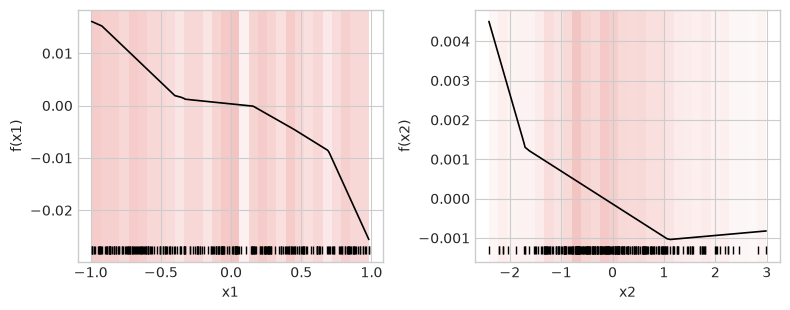

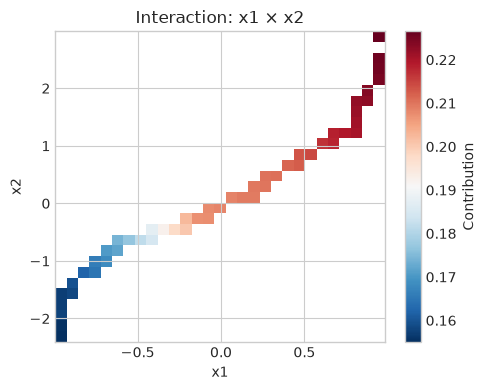

In [2]:
from nampy.models import NAMRegressor

nam = NAMRegressor(
    layer_sizes=[24, 12], dropout=0.0,
    numerical_preprocessing="minmax",
    categorical_preprocessing="one-hot",
    interactions=[("x1", "x2")],
)
fit_and_evaluate("NAM", nam)

components = nam.predict_components(X_test, center=True)
display(architecture_summary(nam))
display(nam.term_importance(X_test, center=True))
display(nam.explain_terms(X_test, max_bins=18, center=True).head(12))
nam.plot_terms(X_test, center=True, rug=True, pages=1)
nam.plot_interactions(X_test)


## 2. Scope of architecture checks

The [task and distribution report](04_distributional_models.ipynb) owns the
broad architecture/task matrix. Here every fitted architecture must reconstruct
its additive predictor on the held-out rows within absolute tolerance `1e-5`.
Specialized probes below additionally inspect compression, bases, and local
expansions. These runs leave tuning, convergence and comparative performance
untested.


In [3]:
# Task coverage is reported in 04_distributional_models.ipynb.


## 3. Feature networks: NAM

NAM assigns one multilayer perceptron to each source feature and optional
networks to explicit interactions. Width, feature-layer type, dropout,
normalization, and regularization control complexity. Centering produces
stable shape functions but does not make observational effects causal.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [4]:
display({key: nam.get_params(deep=False)[key] for key in ("layer_sizes", "dropout", "interactions")})


{'layer_sizes': [24, 12], 'dropout': 0.0, 'interactions': [('x1', 'x2')]}

## 4. Explicit interactions and compression: SIAN

Fit the specified pairwise interaction, then compare predictions before and
after compression (absolute tolerance `1e-5`). This bypasses interaction
discovery and supplies no evidence about a selection procedure.


In [5]:
from nampy.models import SIANRegressor
sian = SIANRegressor(layer_sizes=[12], interactions=[("x1", "x2")])
display(fit_and_evaluate("SIAN", sian))
before = sian.predict(X_test)
sian.compress_terms()
compression_difference = float(np.max(np.abs(before - sian.predict(X_test))))
display({"maximum prediction change after compression": compression_difference})
sian.block_mask_terms()

assert np.isfinite(compression_difference) and compression_difference <= 1e-5


{'model': 'SIAN',
 'metric': 'R2',
 'test score': 0.32512243941995655,
 'fit seconds': 1.1160395400365815,
 'terms': 4,
 'interactions': 1,
 'parameters': 485,
 'reconstruction error': 9.068753570318222e-08,
 'reconstruction valid': True}

{'maximum prediction change after compression': 1.1920928955078125e-07}

## 5. Group sparsity: SNAM

SNAM adds a group-lasso penalty over feature and optionally interaction
subnetworks. Whole terms can be driven toward zero. Inspect group norms
across a regularization path; a larger penalty favors a smaller model but
can underfit weak real effects.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [6]:
from nampy.models import SNAMRegressor
snam = SNAMRegressor(layer_sizes=[12], dropout=0.0, group_lasso_lambda=0.02)
display(fit_and_evaluate("SNAM", snam))
norms = snam.group_norms()
selected = snam.model.model.selected_groups(threshold=1e-6)
assert all(np.isfinite(value) and value >= 0 for value in norms.values())
assert set(selected) == {name for name, value in norms.items() if value > 1e-6}
display(norms)
display(selected)


{'model': 'SNAM',
 'metric': 'R2',
 'test score': -0.5627082160201957,
 'fit seconds': 0.9761596900061704,
 'terms': 3,
 'interactions': 0,
 'parameters': 568,
 'reconstruction error': 5.820766091346741e-08,
 'reconstruction valid': True}

{'x1': 2.0205485820770264,
 'x2': 2.1690292358398438,
 'group': 2.986497163772583}

['x1', 'x2', 'group']

## 6. Random Fourier features: GPNAM

GPNAM approximates stationary Gaussian-process kernels with random Fourier
features, then solves a regularized linear problem. Kernel widths govern
smoothness; the feature count governs approximation fidelity. Pairwise
RFF blocks provide GP-NA2M-style interactions.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [7]:
from nampy.models import GPNAMRegressor
gpnam = GPNAMRegressor(rff_num_feat=12, interactions=[("x1", "x2")])
display(fit_and_evaluate("GPNAM", gpnam))
basis = gpnam.model.model.basis_metadata()
assert len(basis["frequencies"]) == 12
assert np.isfinite(basis["frequencies"]).all()
assert np.isfinite(basis["kernel_widths"]).all() and (basis["kernel_widths"] > 0).all()
display(basis)


{'model': 'GPNAM',
 'metric': 'R2',
 'test score': 0.45875205119442497,
 'fit seconds': 0.056323079974390566,
 'terms': 6,
 'interactions': 1,
 'parameters': 73,
 'reconstruction error': 2.505257725715637e-07,
 'reconstruction valid': True}

{'feature_names': ('x1', 'x2', 'group[0]', 'group[1]', 'group[2]'),
 'interaction_names': ('x1:x2',),
 'kernel_widths': array([0.02407884, 0.04237896, 0.01980659, 0.01920233, 0.01989572],
       dtype=float32),
 'frequencies': array([-1.4260769 , -1.0200763 , -0.73631597, -0.5024022 , -0.2933812 ,
        -0.09655861,  0.09655868,  0.29338127,  0.50240225,  0.73631597,
         1.0200763 ,  1.4260769 ], dtype=float32),
 'phases': array([[1.5707964, 2.0943952, 0.       , 2.617994 , 3.6651917, 4.712389 ,
         5.759587 , 3.1415927, 4.1887903, 0.5235988, 5.235988 , 1.0471976],
        [3.6651917, 3.1415927, 4.712389 , 2.617994 , 0.5235988, 1.5707964,
         5.235988 , 2.0943952, 0.       , 1.0471976, 4.1887903, 5.759587 ],
        [5.759587 , 4.1887903, 5.235988 , 2.617994 , 3.6651917, 0.5235988,
         3.1415927, 1.0471976, 0.       , 2.0943952, 4.712389 , 1.5707964],
        [3.6651917, 0.       , 4.1887903, 1.5707964, 5.759587 , 2.0943952,
         1.0471976, 2.617994 , 4.712389

## 7. ELM boosting: IGANN

IGANN begins with a linear fit and sequentially adds feature-wise extreme
learning machine stages with fixed random hidden weights. Regression and
binary classification use its native boosting solver. Interactions are
not advertised by the registry.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [8]:
from nampy.models import IGANNRegressor
igann = IGANNRegressor(n_hid=6, n_estimators=4, early_stopping=2)
display(fit_and_evaluate("IGANN", igann))
history = igann.training_history_
assert 1 <= igann.n_estimators_ <= 4
assert all(np.isfinite(values).all() for values in history.values())
display(history)


{'model': 'IGANN',
 'metric': 'R2',
 'test score': 0.5608361517657919,
 'fit seconds': 0.053830370015930384,
 'terms': 3,
 'interactions': 0,
 'parameters': 61,
 'reconstruction error': 1.7881393432617188e-07,
 'reconstruction valid': True}

{'train_loss': (0.40243983268737793,
  0.38003626465797424,
  0.3744937479496002,
  0.37389856576919556),
 'val_loss': (0.352098286151886,
  0.3369818329811096,
  0.3320246636867523,
  0.33220773935317993)}

## 8. Shared learned bases: NBM

NBM learns reusable unary bases and composes them into n-ary subnetworks.
Dense mode evaluates configured orders; sparse mode can ignore inactive
inputs. Shared bases reduce duplicated representation learning and make
higher-order structure explicit.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [9]:
from nampy.models import NBMRegressor
nbm = NBMRegressor(layer_sizes=[12], num_bases=6, nary=[1, 2], dropout=0.0, bases_dropout=0.0)
display(fit_and_evaluate("NBM", nbm))
display({"orders": nbm.get_params(deep=False)["nary"], "featurizer": nbm.get_params(deep=False)["featurizer"]})


{'model': 'NBM',
 'metric': 'R2',
 'test score': -0.3500786440502892,
 'fit seconds': 1.8678435600013472,
 'terms': 15,
 'interactions': 1,
 'parameters': 409,
 'reconstruction error': 1.138541848022534e-07,
 'reconstruction valid': True}

{'orders': [1, 2], 'featurizer': 'conv1d'}

## 9. Polynomial structure and local importance: SPAM

SPAM represents low-rank polynomial interactions. `ranks` configures the polynomial heads and their factorization widths;
`reg_order` controls the norm used for regularization, not polynomial degree. Because polynomial
terms can be evaluated row by row, SPAM exposes local term importance in
addition to global mean-absolute contribution.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [10]:
from nampy.models import SPAMRegressor
spam = SPAMRegressor(ranks=[6], reg_order=2, regularization_scale=1e-5)
display(fit_and_evaluate("SPAM", spam))
local = spam.local_term_importance(X_test.iloc[:3], top_k=4)
assert len(local) == 3 and all(len(row) <= 4 for row in local)
assert all(np.isfinite(term["contribution"]) for row in local for term in row)
display(local)


{'model': 'SPAM',
 'metric': 'R2',
 'test score': 0.05551093841525323,
 'fit seconds': 1.0309233000152744,
 'terms': 6,
 'interactions': 0,
 'parameters': 42,
 'reconstruction error': 3.725290304013029e-08,
 'reconstruction valid': True}

[[{'term': ('x1',), 'order': 1, 'contribution': 0.21948029100894928},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': 0.013601006008684635},
  {'term': ('x2',), 'order': 1, 'contribution': 0.0028191778110340238}],
 [{'term': ('x1',), 'order': 1, 'contribution': 0.20878258161246777},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x2',), 'order': 1, 'contribution': 0.03247865196317434},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': 0.013265402056276798}],
 [{'term': ('x1',), 'order': 1, 'contribution': -0.18620585463941097},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': -0.011570941656827927},
  {'term': ('x1', 'x2'), 'order': 2, 'contribution': 0.007149345241487026}]]

## 10. Non-crossing conditional quantiles: QNAM

QNAM predicts several conditional quantiles under pinball loss. A
monotone transform parameterizes successive quantile increments, making
non-crossing structural rather than a post-hoc sort. The gap between two
quantiles forms a conditional prediction interval.
This probe checks ordering on held-out covariates; the task matrix checks
training-row outputs and loss. No held-out calibration claim is made.


In [11]:
from nampy.models import QNAMLSS
qnam = QNAMLSS(layer_sizes=[12], dropout=0.0, distributional_kwargs={"quantiles": [0.1, 0.5, 0.9]})
display(fit_and_evaluate("QNAM", qnam))
predicted_quantiles = qnam.predict(X_test)
minimum_gap = float(np.diff(predicted_quantiles, axis=1).min())
display({"minimum adjacent quantile gap": minimum_gap})

assert np.isfinite(predicted_quantiles).all() and minimum_gap >= 0


{'model': 'QNAM',
 'metric': 'negative pinball loss',
 'test score': -2.3104708194732666,
 'fit seconds': 0.8427921700058505,
 'terms': 3,
 'interactions': 0,
 'parameters': 648,
 'reconstruction error': 4.172325134277344e-07,
 'reconstruction valid': True}

{'minimum adjacent quantile gap': 2.4456844329833984}

## 11. Cubic spline layers: SplineNAM

SplineNAM replaces generic feature networks with cubic spline layers.
Knot count determines capacity; a smoothing penalty discourages rough
coefficients. Interaction spline layers extend the same idea to named
feature pairs. Derivative plots reveal how the penalty changes local
slopes.

The code below records the configuration and observed outputs; additive
reconstruction must satisfy the shared acceptance condition in section 2.
See the [model reference](../../models/index.rst) for architectural details.


In [12]:
from nampy.models import SplineNAMRegressor
spline_nam = SplineNAMRegressor(n_knots=6, smoothing=0.01, interactions=[("x1", "x2")])
display(fit_and_evaluate("SplineNAM", spline_nam))


{'model': 'SplineNAM',
 'metric': 'R2',
 'test score': -0.5333259987049668,
 'fit seconds': 6.913141730008647,
 'terms': 4,
 'interactions': 1,
 'parameters': 29,
 'reconstruction error': 7.450580596923828e-08,
 'reconstruction valid': True}

## 12. Summary of interface checks

Models use stable alphabetical order. The figure reports component
reconstruction against the acceptance threshold and coverage of the shared
checks. Scores and runtimes remain secondary diagnostics in the table;
small training budgets do not support a performance ranking.


In [13]:
comparison = pd.DataFrame(comparison_rows).sort_values("model", key=lambda col: col.str.lower())
comparison


,model,metric,test score,fit seconds,terms,interactions,parameters,reconstruction error,reconstruction valid
3,GPNAM,R2,0.458752,0.056323,6,1,73,2.505258e-07,True
4,IGANN,R2,0.560836,0.053830,3,0,61,1.788139e-07,True
0,NAM,R2,-0.210627,1.083081,4,1,1517,9.313226e-08,True
5,NBM,R2,-0.350079,1.867844,15,1,409,1.138542e-07,True
7,QNAM,negative pinball loss,-2.310471,0.842792,3,0,648,4.172325e-07,True
1,SIAN,R2,0.325122,1.116040,4,1,485,9.068754e-08,True
2,SNAM,R2,-0.562708,0.976160,3,0,568,5.820766e-08,True
6,SPAM,R2,0.055511,1.030923,6,0,42,3.725290e-08,True
8,SplineNAM,R2,-0.533326,6.913142,4,1,29,7.450581e-08,True


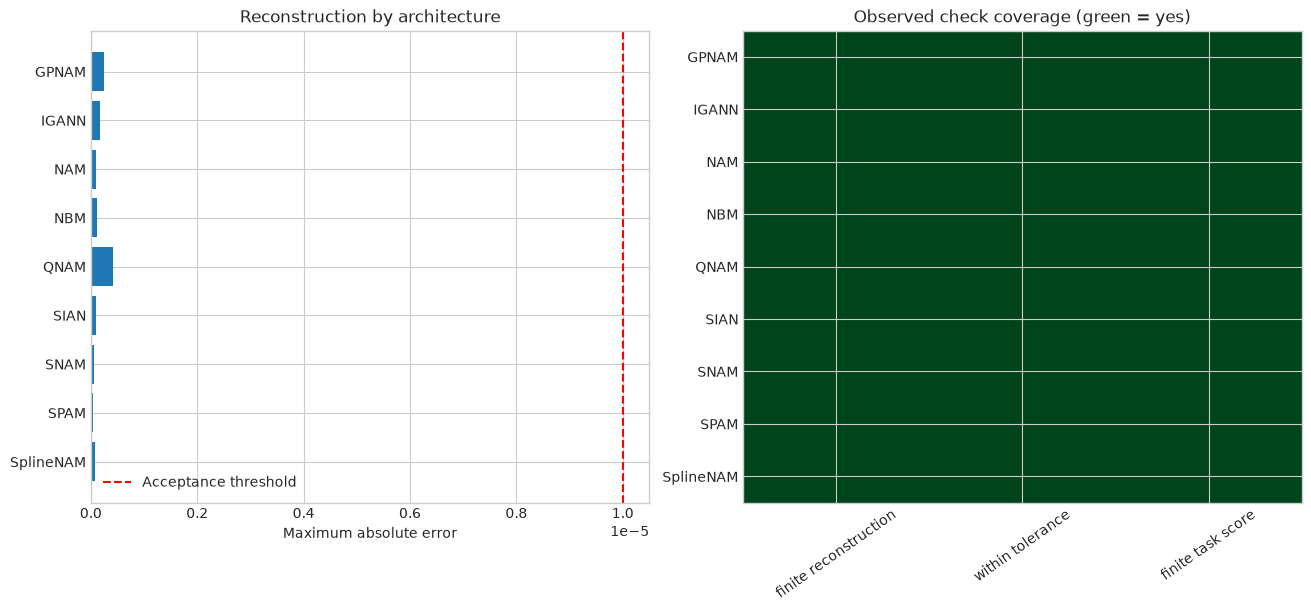

,model/task,category,message,expected,count
0,NAM,FutureWarning,"`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.",False,2
1,NAM,PossibleUserWarning,The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.,False,1
2,NAM,PossibleUserWarning,The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.,False,1
3,NAM,UserWarning,"You called `self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`",False,60
4,NAM,UserWarning,"You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`",False,20
5,NBM,FutureWarning,"`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.",False,2
6,NBM,PossibleUserWarning,The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.,False,1
7,NBM,PossibleUserWarning,The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.,False,1
8,NBM,UserWarning,"You called `self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`",False,60
9,NBM,UserWarning,"You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`",False,20


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
axes[0].barh(comparison["model"], comparison["reconstruction error"])
axes[0].axvline(1e-5, color="red", linestyle="--", label="Acceptance threshold")
axes[0].set(title="Reconstruction by architecture", xlabel="Maximum absolute error")
axes[0].legend()
axes[0].invert_yaxis()
coverage = pd.DataFrame({
    "finite reconstruction": np.isfinite(comparison["reconstruction error"]),
    "within tolerance": comparison["reconstruction valid"],
    "finite task score": np.isfinite(comparison["test score"]),
}, index=comparison.index)
axes[1].imshow(coverage.to_numpy(dtype=int), vmin=0, vmax=1, cmap="Greens", aspect="auto")
axes[1].set(yticks=range(len(comparison)), yticklabels=comparison["model"],
            xticks=range(len(coverage.columns)), xticklabels=coverage.columns,
            title="Observed check coverage (green = yes)")
axes[1].tick_params(axis="x", rotation=35)
plt.show()
plt.close(fig)
warning_report = pd.DataFrame(warning_rows, columns=["model/task", "category", "message", "expected"])
warning_summary = (warning_report.groupby(["model/task", "category", "message", "expected"],
                                          dropna=False).size().reset_index(name="count"))
display(warning_summary if len(warning_summary) else "No fit warnings captured.")
